In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

In [12]:
def haar_step(image):

    block = np.asarray(image, dtype=np.float32)


    left_tops = block[0::2, 0::2]
    right_tops = block[0::2, 1::2]
    left_bots = block[1::2, 0::2]
    right_bots = block[1::2, 1::2]

    avg = (left_tops + right_tops + left_bots + right_bots) / 4.0
    LR_avg = (left_tops + left_bots - right_tops - right_bots) / 4.0
    TB_avg = (left_tops + right_tops - left_bots - right_bots) / 4.0
    DIAG_avg = (left_tops + right_bots - right_tops - left_bots) / 4.0

    return avg, LR_avg, TB_avg, DIAG_avg



def normalize(arr):
    arr_min, arr_max = arr.min(), arr.max()
    if arr_max - arr_min < 1e-8:
        return np.zeros_like(arr, dtype=np.uint8)
    return np.uint8((arr - arr_min) / (arr_max - arr_min) * 255)


def show_4_imgs(A11, A12, A21, A22):

    norm_A11 = normalize(A11)
    norm_A12 = normalize(np.abs(A12))
    norm_A21 = normalize(np.abs(A21))
    norm_A22 = normalize(np.abs(A22))

    fig, ax = plt.subplots(1, 4, figsize=(15, 5))

    ax[0].imshow(norm_A11, cmap="gray", vmin=0, vmax=255)
    ax[0].set_title("Среднее")

    ax[1].imshow(norm_A12, cmap="gray", vmin=0, vmax=255)
    ax[1].set_title("Вертикальные перепады")

    ax[2].imshow(norm_A21, cmap="gray", vmin=0, vmax=255)
    ax[2].set_title("Горизонтальные перепады")
    ax[3].imshow(norm_A22, cmap="gray", vmin=0, vmax=255)
    ax[3].set_title("Диагональные перепады")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()



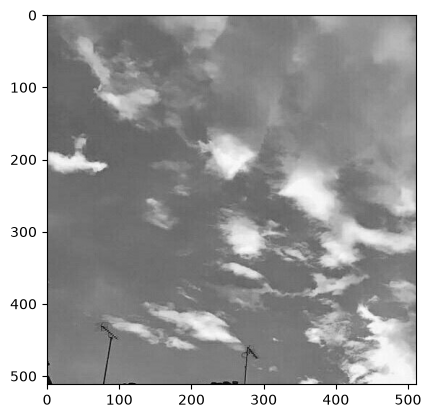

In [13]:
img = cv.imread('sky.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

#### 1 ступень

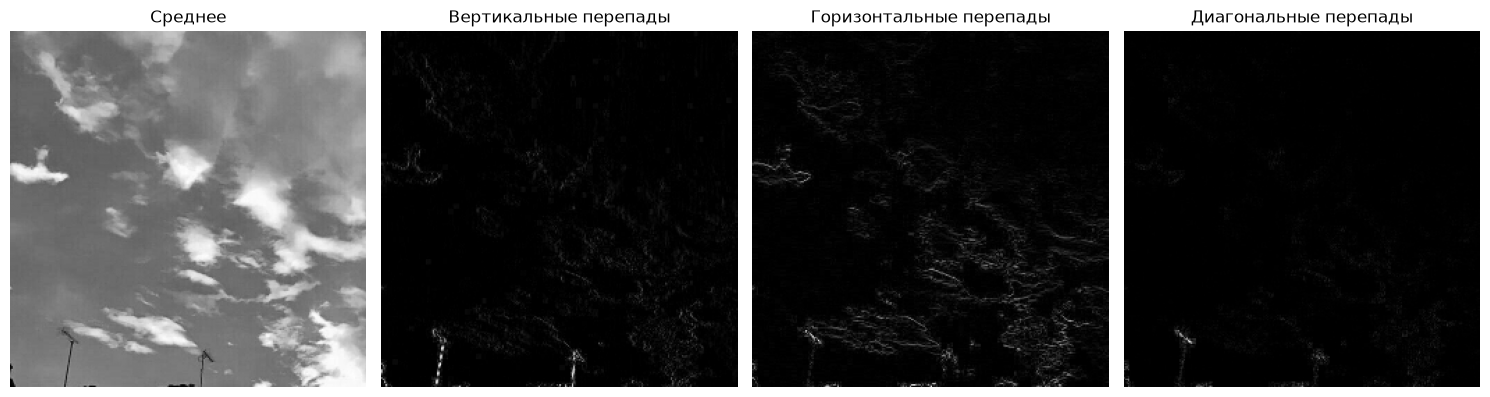

In [14]:
step1_A11, step1_A12, step1_A21, step1_A22 = haar_step(img)
show_4_imgs(step1_A11, step1_A12, step1_A21, step1_A22)

#### 2 ступень

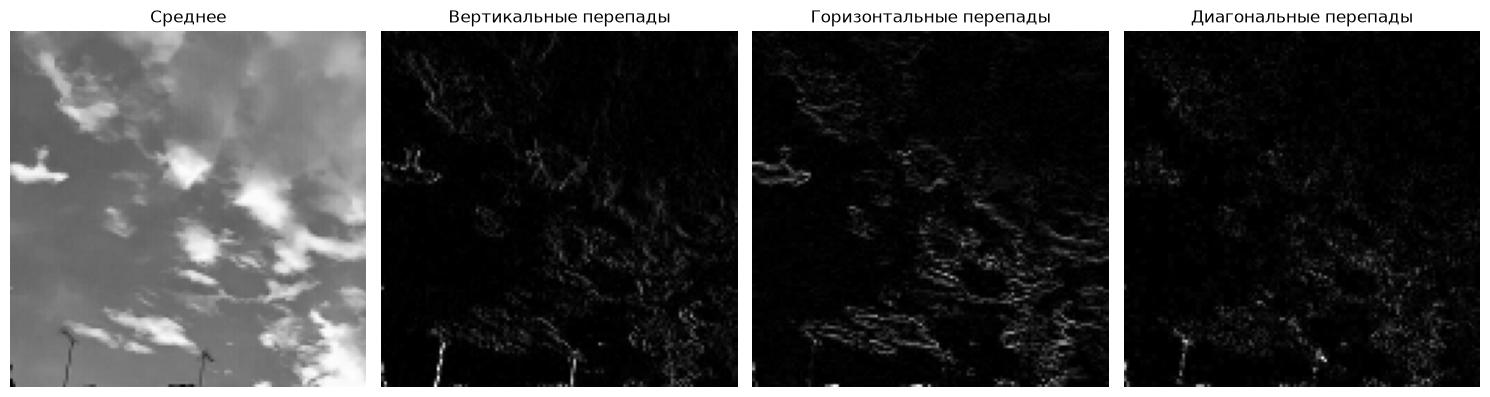

In [15]:
step2_A11, step2_A12, step2_A21, step2_A22 = haar_step(step1_A11)
show_4_imgs(step2_A11, step2_A12, step2_A21, step2_A22)

#### 3 ступень

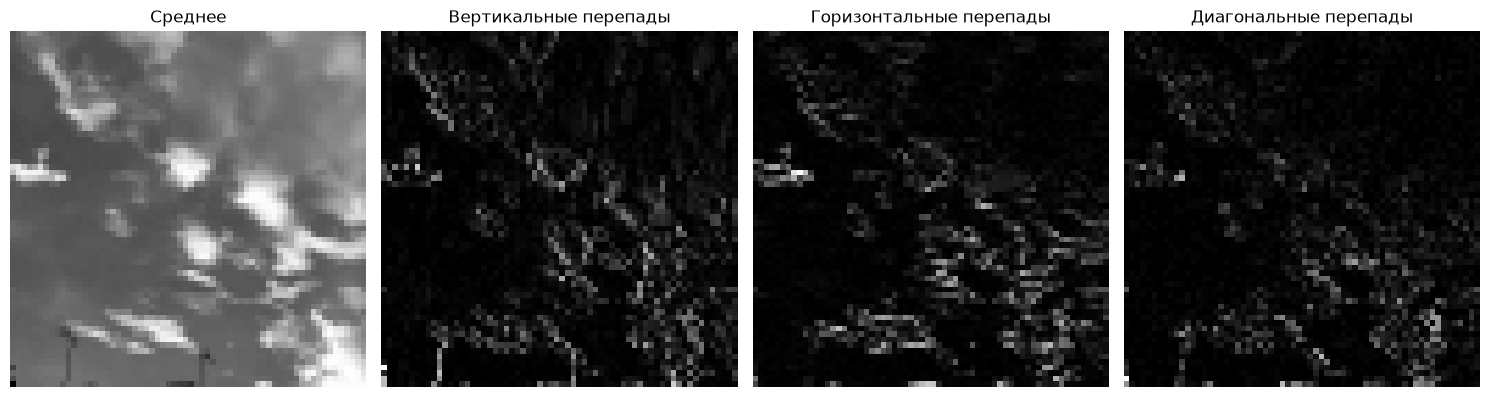

In [16]:
step3_A11, step3_A12, step3_A21, step3_A22 = haar_step(step2_A11)
show_4_imgs(step3_A11, step3_A12, step3_A21, step3_A22)